# Group Project Part 2: Discovering Patterns in SLCM Community Needs
**CS430: Machine Learning**

Team members: Aidan Cissell and Jayden West

## 1. Import libraries

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

## 2. Load the prepared files
`zip_code` must be read as text, otherwise leading digits and ZIP meaning are lost.

In [44]:
profiles = pd.read_csv('SLCM_part2_intake_profiles_clean.csv', dtype={'zip_code': str})
members  = pd.read_csv('SLCM_part2_household_members_clean.csv')
subs     = pd.read_csv('SLCM_part2_care_path_subtickets.csv')
dictionary = pd.read_csv('SLCM_part2_data_dictionary.csv')
cleaning_log = pd.read_csv('SLCM_part2_cleaning_log.csv')

print('Profiles:', profiles.shape, '| Members:', members.shape, '| Sub-tickets:', subs.shape)
print('Profiles + sub-tickets =', len(profiles) + len(subs), '(original masked file had 639 rows)')

Profiles: (426, 85) | Members: (993, 9) | Sub-tickets: (213, 10)
Profiles + sub-tickets = 639 (original masked file had 639 rows)


## 3. Read the data dictionary and cleaning log first
The `role` column tells you which columns are candidate need features, which are context for profiling, which are data-quality flags, and which must not be used as clustering inputs.

In [45]:
dictionary['role'].value_counts()

,count
role,
Need indicator - candidate feature,36
"Context - use to profile clusters, not as input",27
Data-quality flag,8
Identifier / structure - never a clustering input,7
"Sensitive - describe only, not a clustering input",7


In [46]:
pd.set_option('display.max_colwidth', 120)
dictionary[['column', 'role', 'description', 'pct_missing']]

,column,role,description,pct_missing
0,issue_key,Identifier / structure - never a clustering input,Jira ticket number (NEIG-#####); one row per profile ticket,0.0
1,pid,Identifier / structure - never a clustering input,Approximate person ID built by name matching; links repeat tickets,0.0
2,pid_match_basis,Data-quality flag,How PID was matched; all profile tickets are 'Name + DOB' (name-only matches occur on sub-tickets),0.0
3,issue_type,Identifier / structure - never a clustering input,New Profile / Connected Neighbor Profile / Flourishing Neighbor Profile,0.0
4,case_status,"Context - use to profile clusters, not as input","Jira workflow status at export (e.g. Referral Only, Goal Attained). Process status, not a family outcome",0.0
5,case_status_category,"Context - use to profile clusters, not as input",To Do / In Progress / Done,0.0
6,is_duplicate_ticket,Data-quality flag,Yes if staff marked the ticket 'Duplicate' (12),0.0
7,created_date,Identifier / structure - never a clustering input,Date ticket was created,0.0
8,intake_date,Identifier / structure - never a clustering input,Intake date recorded on the form,0.0
9,intake_month,"Context - use to profile clusters, not as input",YYYY-MM of intake (Jan-Aug 2026),0.0


In [47]:
cleaning_log[['step', 'field', 'rule', 'rows_affected']]

,step,field,rule,rows_affected
0,0,(file),"Loaded 639 rows x 93 cols (intake), 993 rows (members)",639
1,1,Issue Type,Profile tickets (New / Connected / Flourishing Neighbor Profile) -> profiles file; all other Issue Types -> care-pat...,213
2,1,Parent key,Sub-tickets whose parent ticket is not in the export kept in sub-ticket file with parent_in_file = No,13
3,2,PID (sub-tickets),Added pid_matches_parent: sub-ticket PID differs from its parent profile's PID,31
4,3,Status,Status == 'Duplicate' flagged in is_duplicate_ticket (not removed),12
5,3,Created / Intake Date,Parsed 'dd/Mon/yy h:mm AM' text to ISO dates; added intake_month,426
6,3,PID,"Added pid_n_profile_tickets, pid_ticket_seq (1 = earliest), pid_is_latest_profile, pid_n_all_tickets (profiles + sub...",426
7,3,(sub-tickets),Counted linked care-path sub-tickets per profile: n_care_path_subtickets and sub_<group> counts,165
8,4,Zip Code,Kept first 5 digits of ZIP+4 values (e.g. 40214-5715 -> 40214),5
9,4,Zip Code,Non-numeric ZIP '402q1' set to missing,1


## 4. Extra setup

In [48]:
# extra imports and settings used below
import os
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.optimize import linear_sum_assignment

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

seed = 42
os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

# role of each column from the data dictionary
roles = dict(zip(dictionary['column'].astype(str), dictionary['role'].astype(str).str.lower()))

In [49]:
# full list of columns with their dictionary role (no row values)
print(dictionary[['column', 'role', 'pct_missing']].to_string())

                          column                                               role  pct_missing
0                      issue_key  Identifier / structure - never a clustering input          0.0
1                            pid  Identifier / structure - never a clustering input          0.0
2                pid_match_basis                                  Data-quality flag          0.0
3                     issue_type  Identifier / structure - never a clustering input          0.0
4                    case_status    Context - use to profile clusters, not as input          0.0
5           case_status_category    Context - use to profile clusters, not as input          0.0
6            is_duplicate_ticket                                  Data-quality flag          0.0
7                   created_date  Identifier / structure - never a clustering input          0.0
8                    intake_date  Identifier / structure - never a clustering input          0.0
9                   intake_mon

In [50]:
# type, missingness and number of distinct values for every profile column
structure = pd.DataFrame({
    'dtype': profiles.dtypes.astype(str),
    'missing_pct': (profiles.isna().mean() * 100).round(1),
    'n_unique': profiles.nunique()
})
print(structure.to_string())

                                dtype  missing_pct  n_unique
issue_key                      object          0.0       426
pid                            object          0.0       395
pid_match_basis                object          0.0         1
issue_type                     object          0.0         3
case_status                    object          0.0        10
case_status_category           object          0.0         3
is_duplicate_ticket            object          0.0         2
created_date                   object          0.0       160
intake_date                    object          0.0       158
intake_month                   object          0.0         8
pid_n_profile_tickets           int64          0.0         4
pid_ticket_seq                  int64          0.0         4
pid_is_latest_profile          object          0.0         2
pid_n_all_tickets               int64          0.0         5
sub_basic_needs                 int64          0.0         3
sub_housing_navigation  

TASK 0

1. Briefly recap two important Part 1 findings and one data-quality limitation. Explain how they influence your Part 2 approach.

Two things we found in Part 1 are that employed families still rely on SNAP benefits even though they are receiving income from work, and that only 27 out of 150 repeat people had housing recorded more than once. Because a job alone did not mean a family was stable, employment status and income are both clustering inputs in Part 2. Because housing was rarely recorded more than once, there is one row per person instead of one row per ticket, so repeat visitors aren't counted twice. One limitation was extreme data, like a $125,100 rent entry. In Part 2, income goes on a log scale and $0 gets its own flag, so a few huge values or zero values don't control the clusters.

2. Define your observational unit (one ticket, one person, or another defensible unit). Describe how you treat Issue Type, tickets flagged is_duplicate_ticket, repeat PID values (see pid_ticket_seq and pid_is_latest_profile) and records missing core fields. Start from 426 profile tickets and 395 PIDs, report the number of observations that remain, and do not silently drop records.

In [51]:
# starting counts: profile tickets and distinct people
print('profile tickets:', len(profiles))
print('distinct issue keys:', profiles['issue_key'].nunique())
print('distinct pids:', profiles['pid'].nunique())
print('missing pid:', profiles['pid'].isna().sum())

profile tickets: 426
distinct issue keys: 426
distinct pids: 395
missing pid: 0


In [52]:
# helper that reads true/false flags stored as text, numbers or booleans
def to_bool(series):
    return series.astype(str).str.strip().str.lower().isin(['true', '1', '1.0', 'yes', 'y'])


# ticket types and duplicate flags
print(profiles['issue_type'].value_counts(dropna=False))
print()
print(profiles['is_duplicate_ticket'].value_counts(dropna=False))
print()
print(pd.crosstab(profiles['issue_type'], to_bool(profiles['is_duplicate_ticket']), margins=True))

issue_type
New Profile                     378
Connected Neighbor Profile       44
Flourishing Neighbor Profile      4
Name: count, dtype: int64

is_duplicate_ticket
No     414
Yes     12
Name: count, dtype: int64

is_duplicate_ticket           False  True  All
issue_type                                    
Connected Neighbor Profile       44     0   44
Flourishing Neighbor Profile      4     0    4
New Profile                     366    12  378
All                             414    12  426


In [53]:
# repeat contact: how many tickets each person has, and the latest-profile flag
tickets_per_pid = profiles.groupby('pid')['issue_key'].count()
print('tickets per pid:')
print(tickets_per_pid.value_counts().sort_index())
print()
print('pid_ticket_seq:')
print(profiles['pid_ticket_seq'].value_counts(dropna=False).sort_index())
print()
print('pid_is_latest_profile:')
print(profiles['pid_is_latest_profile'].value_counts(dropna=False))

if 'pid_n_profile_tickets' in profiles.columns:
    print()
    print('pid_n_profile_tickets:')
    print(profiles['pid_n_profile_tickets'].value_counts(dropna=False).sort_index())

tickets per pid:
issue_key
1    368
2     24
3      2
4      1
Name: count, dtype: int64

pid_ticket_seq:
pid_ticket_seq
1    395
2     27
3      3
4      1
Name: count, dtype: int64

pid_is_latest_profile:
pid_is_latest_profile
Yes    395
No      31
Name: count, dtype: int64

pid_n_profile_tickets:
pid_n_profile_tickets
1    368
2     48
3      6
4      4
Name: count, dtype: int64


In [54]:
# build the analysis table and record the row count after each step
unit = 'person'

flow = []
flow.append(('profile tickets loaded', len(profiles)))

work = profiles.copy()
work['dup_flag'] = to_bool(work['is_duplicate_ticket'])
work = work[~work['dup_flag']].copy()
flow.append(('removed tickets flagged is_duplicate_ticket', len(work)))

# people with no pid keep their own ticket as the unit
work['unit_id'] = work['pid'].astype(str)
no_pid = work['pid'].isna()
work.loc[no_pid, 'unit_id'] = 'ticket_' + work.loc[no_pid, 'issue_key'].astype(str)

# number of profiles each person has (describe only)
contacts = work.groupby('unit_id')['issue_key'].count().rename('n_profiles')
work = work.join(contacts, on='unit_id')

if unit == 'person':
    work['seq_num'] = pd.to_numeric(work['pid_ticket_seq'], errors='coerce').fillna(1)
    work = work.sort_values(['unit_id', 'seq_num'])
    analysis = work.groupby('unit_id').tail(1).copy()
    flow.append(('kept latest profile per person', len(analysis)))
else:
    analysis = work.copy()

analysis = analysis.reset_index(drop=True)
print(pd.DataFrame(flow, columns=['step', 'rows']).to_string(index=False))
print()
print('units with more than one profile:', (analysis['n_profiles'] > 1).sum())

                                       step  rows
                     profile tickets loaded   426
removed tickets flagged is_duplicate_ticket   414
             kept latest profile per person   389

units with more than one profile: 21


We used one row per person because repeat contacts would otherwise be counted more than once and pull the clusters toward those people. We started with 426 profile tickets and 395 PIDs. 12 tickets flagged as duplicates were removed, leaving 414, and then we kept each person's latest profile, leaving 389. 21 people had more than one profile, and that count is only used to describe the clusters in Question 3, not as a clustering input. Issue Type wasn't used as an input because it reflects where the person is in SLCM's process, not their needs. There were 0 people missing all core fields, so nothing was dropped at that step. The final count was 389 people.

TASK 1

3. Choose a small, justified set of features describing needs. Possible candidates include housing status, eviction status, employment status, income amount, number of children/household members, past-due rent, and ZIP code. Do not use Issue key, PID or other identifiers as clustering inputs. Use sensitive fields only to describe clusters, never to define them.

In [55]:
# candidate need features: search keys in priority order, and words that rule a column out
spec = {
    'housing_status': {'kind': 'cat', 'keys': ['housing_status', 'housing status', 'housing'], 'exclude': ['proxy', 'urgent', 'section', 'voucher', 'flag']},
    'eviction_status': {'kind': 'cat', 'keys': ['eviction_status', 'eviction status', 'evict'], 'exclude': ['proxy', 'urgent', 'flag', 'date']},
    'employment_status': {'kind': 'cat', 'keys': ['employment_status', 'employment status', 'employment', 'employ'], 'exclude': ['employer', 'flag']},
    'income_amount': {'kind': 'num', 'keys': ['income_amount', 'monthly_income', 'income amount', 'income'], 'exclude': ['source', 'src', 'causation', 'loss', 'flag', 'annual', 'zero', 'missing', 'is_']},
    'household_size': {'kind': 'num', 'keys': ['household_size', 'household size', 'additional_household', 'additional household', 'household_members', 'household'], 'exclude': ['flag', 'more_than', 'age']},
    'num_children': {'kind': 'num', 'keys': ['num_children', 'number_of_children', 'children', 'child'], 'exclude': ['flag', 'age', 'more_than']},
    'past_due_rent': {'kind': 'num', 'keys': ['past_due_rent', 'past_due', 'past due', 'arrears'], 'exclude': ['high_arrears', '3000', 'flag', 'missing', 'recorded', 'utility']}
}

# put exact column names here to override a wrong automatic pick, e.g. {"income_amount": "monthly_income_clean"}
manual = {}

use_past_due = False

blocked_roles = ['ident', 'sensitive', 'quality', 'flag']


def role_blocked(col):
    role = roles.get(col, '')
    if len(roles) > 0 and 'need' not in role:
        return True
    return any(b in role for b in blocked_roles)


def mostly_numeric(col):
    present = profiles[col].notna().sum()
    if present == 0:
        return False
    raw = profiles[col].replace({'More than 5': 6, 'more than 5': 6})
    vals = pd.to_numeric(raw, errors='coerce')
    return vals.notna().sum() / present >= 0.8


def candidates(name):
    found = []
    for key in spec[name]['keys']:
        for col in profiles.columns:
            low = col.lower()
            if key in low and col not in found:
                if not any(e in low for e in spec[name]['exclude']) and not role_blocked(col):
                    found.append(col)
    return found


chosen = {}
rows = []
for name in spec:
    found = candidates(name)
    pick = None
    if name in manual:
        pick = manual[name]
    else:
        for col in found:
            numeric = mostly_numeric(col)
            if spec[name]['kind'] == 'num' and numeric:
                pick = col
                break
            elif spec[name]['kind'] == 'cat' and not numeric and profiles[col].nunique() <= 30:
                pick = col
                break
    chosen[name] = pick
    rows.append({'feature': name, 'kind': spec[name]['kind'], 'picked column': pick, 'other candidates': [c for c in found if c != pick][:6]})

print(pd.DataFrame(rows).to_string(index=False))

          feature kind           picked column                                                                                              other candidates
   housing_status  cat          housing_status                                                                                               [housing_group]
  eviction_status  cat         eviction_status                                                                                                            []
employment_status  cat       employment_status                                                                                                            []
    income_amount  num          income_monthly                                                                                          [rent_to_income_pct]
   household_size  num household_size_reported [household_size_from_members, additional_household_members, household_repairs_required, household_has_65plus]
     num_children  num       children_17_under            

In [56]:
# copy the picked columns into clean feature columns; unknown categories stay "Unknown", not stable or at risk
num_features = []
cat_features = []
for name, col in chosen.items():
    if col is None:
        continue
    if spec[name]['kind'] == 'num':
        raw = analysis[col].replace({'More than 5': 6, 'more than 5': 6})
        analysis[name] = pd.to_numeric(raw, errors='coerce')
        num_features.append(name)
    else:
        vals = analysis[col].where(analysis[col].notna(), 'Unknown').astype(str).str.strip()
        vals = vals.replace({'': 'Unknown', 'nan': 'Unknown', 'None': 'Unknown'})
        analysis[name] = vals
        cat_features.append(name)

print('numeric:', num_features)
print('categorical:', cat_features)

numeric: ['income_amount', 'household_size', 'num_children', 'past_due_rent']
categorical: ['housing_status', 'eviction_status', 'employment_status']


In [57]:
# do not silently drop: report units missing every core field, then remove them
core = [f for f in ['housing_status', 'employment_status', 'income_amount'] if f in num_features + cat_features]
missing_core = pd.Series(True, index=analysis.index)
for f in core:
    if f in num_features:
        missing_core = missing_core & analysis[f].isna()
    else:
        missing_core = missing_core & (analysis[f] == 'Unknown')

print('core fields:', core)
print('units missing all core fields:', missing_core.sum())
analysis = analysis[~missing_core].reset_index(drop=True)
flow.append(('removed units missing all core need fields', len(analysis)))
print(pd.DataFrame(flow, columns=['step', 'rows']).to_string(index=False))

core fields: ['housing_status', 'employment_status', 'income_amount']
units missing all core fields: 0
                                       step  rows
                     profile tickets loaded   426
removed tickets flagged is_duplicate_ticket   414
             kept latest profile per person   389
 removed units missing all core need fields   389


We used six features to build the clusters: housing status, eviction status, employment status, monthly income, household size, and number of children. We also kept past-due rent, but only to describe the clusters, because it is missing for about 61% of people since it comes from a separate rent form. We chose these features because they are the needs named in the handout and the data dictionary marks them as need indicators. We left out ZIP code, issue_key, pid, age, race, urgent_housing_proxy, and high_arrears_3000. We left out ZIP code because it describes location rather than need, and it has many different values, which makes it harder to use. issue_key and pid are identifiers, so they can't be clustering inputs. We didn't use age and race because they are sensitive fields and are only used to describe the clusters. urgent_housing_proxy and high_arrears_3000 are also only used to describe the clusters.

4. Create a concise feature table: chosen field, what it represents, its missingness, preparation/encoding choice, and reason for inclusion. Investigate the effect of missing values, zeros and extreme values. Explain any encoding, scaling or transformation you use.

In [58]:
# numeric features: missingness, zeros, spread and skew
num_rows = []
for f in num_features:
    s = analysis[f]
    num_rows.append({
        'feature': f,
        'source column': chosen[f],
        'missing_pct': round(s.isna().mean() * 100, 1),
        'zero_pct': round((s == 0).mean() * 100, 1),
        'min': s.min(),
        'median': s.median(),
        'mean': round(s.mean(), 1),
        'p99': s.quantile(0.99),
        'max': s.max(),
        'skew': round(s.skew(), 2)
    })
print(pd.DataFrame(num_rows).to_string(index=False))

       feature           source column  missing_pct  zero_pct  min  median   mean     p99     max  skew
 income_amount          income_monthly          0.0      31.6  0.0   924.0 1173.9 5161.76  9000.0  1.50
household_size household_size_reported          0.0       1.3  0.0     4.0    3.8   11.12    12.0  1.21
  num_children       children_17_under          0.0       6.4  0.0     2.0    2.3    6.00     6.0  0.69
 past_due_rent           past_due_rent         61.4       1.3  0.0  1885.0 2342.0 7510.00 16000.0  2.87


In [59]:
# categorical features: missingness and category counts
for f in cat_features:
    print(f, '(source:', chosen[f] + ')')
    print(analysis[f].value_counts())
    print()

housing_status (source: housing_status)
housing_status
Renting - rent past due             211
Renting - nothing past due          115
Staying with friends/family          27
Unhoused                             14
Other                                10
Own home - nothing past due           5
Own home - mortgage past due          4
Extended-stay hotel / short-term      3
Name: count, dtype: int64

eviction_status (source: eviction_status)
eviction_status
Not being evicted          233
Currently being evicted     99
Unknown                     57
Name: count, dtype: int64

employment_status (source: employment_status)
employment_status
Unemployed but want to find work                       175
Employed                                               107
Employed, but need more hours and/or different work     53
Other                                                   28
Unemployed and not looking for work                     26
Name: count, dtype: int64



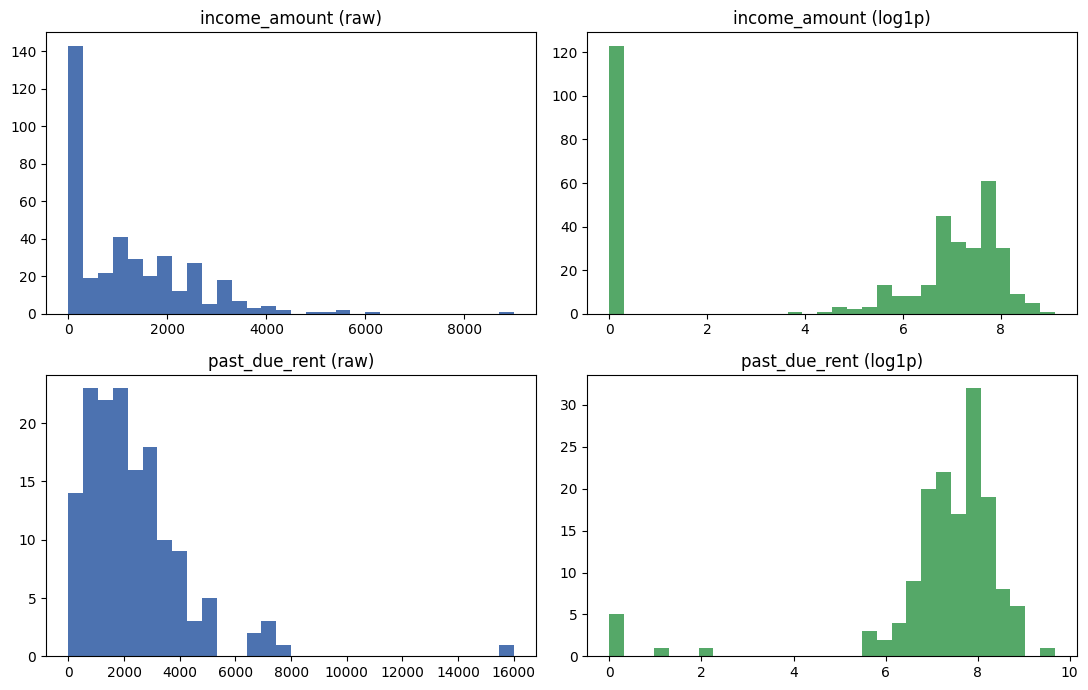

In [60]:
# distribution of income and past-due rent before and after a log transform
money_cols = [f for f in ['income_amount', 'past_due_rent'] if f in num_features]
if len(money_cols) > 0:
    fig, axes = plt.subplots(len(money_cols), 2, figsize=(11, 3.5 * len(money_cols)), squeeze=False)
    for i, f in enumerate(money_cols):
        s = analysis[f].dropna()
        axes[i][0].hist(s, bins=30, color='#4C72B0')
        axes[i][0].set_title(f + ' (raw)')
        axes[i][1].hist(np.log1p(s.clip(lower=0)), bins=30, color='#55A868')
        axes[i][1].set_title(f + ' (log1p)')
    plt.tight_layout()
    plt.savefig('figures/fig_money_distributions.png', dpi=150)
    plt.show()

In [61]:
# inputs: income on a log scale plus a zero flag, counts scaled, categories one-hot encoded
inputs_money = [f for f in ['income_amount'] if f in num_features]
inputs_count = [f for f in num_features if f not in ['income_amount', 'past_due_rent']]
inputs_flag = []
inputs_cat = list(cat_features)

if 'income_amount' in num_features:
    analysis['income_is_zero'] = (analysis['income_amount'] == 0).astype(float)
    inputs_flag.append('income_is_zero')
    if analysis['income_amount'].isna().any():
        analysis['income_missing'] = analysis['income_amount'].isna().astype(float)
        inputs_flag.append('income_missing')

if use_past_due and 'past_due_rent' in num_features:
    inputs_money.append('past_due_rent')
    analysis['past_due_missing'] = analysis['past_due_rent'].isna().astype(float)
    inputs_flag.append('past_due_missing')


def log1p_clip(x):
    return np.log1p(np.clip(x, 0, None))


# missing flags are kept as plain 0/1 columns so they do not outweigh the real need fields
money_pipe = Pipeline([
    ('log', FunctionTransformer(log1p_clip, feature_names_out='one-to-one')),
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

count_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

try:
    onehot = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=5)
except TypeError:
    onehot = OneHotEncoder(handle_unknown='ignore')

cat_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', onehot)
])

parts = []
if len(inputs_money) > 0:
    parts.append(('money', money_pipe, inputs_money))
if len(inputs_count) > 0:
    parts.append(('count', count_pipe, inputs_count))
if len(inputs_flag) > 0:
    parts.append(('flag', 'passthrough', inputs_flag))
if len(inputs_cat) > 0:
    parts.append(('cat', cat_pipe, inputs_cat))

prep = ColumnTransformer(parts, sparse_threshold=0, remainder='drop')

# no target and no train/test split, so the preprocessor is fit on the whole analysis table
x = prep.fit_transform(analysis[inputs_money + inputs_count + inputs_flag + inputs_cat])
try:
    x_names = list(prep.get_feature_names_out())
except Exception:
    x_names = ['f' + str(i) for i in range(x.shape[1])]

print('clustering inputs:', inputs_money + inputs_count + inputs_flag + inputs_cat)
print('matrix shape:', x.shape)
print(x_names)

clustering inputs: ['income_amount', 'household_size', 'num_children', 'income_is_zero', 'housing_status', 'eviction_status', 'employment_status']
matrix shape: (389, 19)
['money__income_amount', 'count__household_size', 'count__num_children', 'flag__income_is_zero', 'cat__housing_status_Other', 'cat__housing_status_Own home - nothing past due', 'cat__housing_status_Renting - nothing past due', 'cat__housing_status_Renting - rent past due', 'cat__housing_status_Staying with friends/family', 'cat__housing_status_Unhoused', 'cat__housing_status_infrequent_sklearn', 'cat__eviction_status_Currently being evicted', 'cat__eviction_status_Not being evicted', 'cat__eviction_status_Unknown', 'cat__employment_status_Employed', 'cat__employment_status_Employed, but need more hours and/or different work', 'cat__employment_status_Other', 'cat__employment_status_Unemployed and not looking for work', 'cat__employment_status_Unemployed but want to find work']


In [62]:
# feature table for the documentation
encoding = {}
for f in inputs_money:
    encoding[f] = 'log1p, median impute, standard scale (missing flag kept as 0/1)' if analysis[f].isna().any() else 'log1p, median impute, standard scale ($0 flag kept as 0/1)'
for f in inputs_count:
    encoding[f] = "already recoded ('More than 5' = 6), median impute, standard scale"
for f in inputs_flag:
    encoding[f] = '0/1 flag, not scaled'
for f in inputs_cat:
    encoding[f] = "missing -> 'Unknown', one-hot (categories under 5 grouped)"
if 'past_due_rent' in num_features and not use_past_due:
    encoding['past_due_rent'] = 'not a clustering input; used to describe clusters'

reasons = {
    'housing_status': 'whether a family has a stable living environment; the main need SLCM addresses',
    'eviction_status': 'whether the family is currently being evicted and at risk of losing housing',
    'employment_status': 'whether the person is working; expands on their financial situation',
    'income_amount': 'monthly income; whether the family can keep up with costs',
    'household_size': 'people in the home; more people means higher costs',
    'num_children': 'children in the family; SLCM focuses on families with young children',
    'income_is_zero': 'marks $0 income separately from low income',
    'past_due_rent': 'rent arrears; describe only because most people are missing it'
}

feature_table = []
for f in list(encoding.keys()):
    src = chosen.get(f, 'derived from income')
    miss = analysis[f].isna().mean() * 100 if f in num_features else (analysis[f] == 'Unknown').mean() * 100 if f in cat_features else 0
    feature_table.append({'feature': f, 'source column': src, 'missing_or_unknown_pct': round(miss, 1), 'preparation': encoding[f], 'reason': reasons.get(f, '')})

feature_table = pd.DataFrame(feature_table)
feature_table.to_csv('outputs/feature_table.csv', index=False)
print(feature_table.to_string(index=False))

          feature           source column  missing_or_unknown_pct                                                        preparation                                                                         reason
    income_amount          income_monthly                     0.0         log1p, median impute, standard scale ($0 flag kept as 0/1)                      monthly income; whether the family can keep up with costs
   household_size household_size_reported                     0.0 already recoded ('More than 5' = 6), median impute, standard scale                             people in the home; more people means higher costs
     num_children       children_17_under                     0.0 already recoded ('More than 5' = 6), median impute, standard scale           children in the family; SLCM focuses on families with young children
   income_is_zero     derived from income                     0.0                                               0/1 flag, not scaled                    

**Reasons for each feature:**
- housing_status: shows whether a family has a stable living environment or not. This is important because it is the main need SLCM addresses.
- eviction_status: shows whether the family is currently being evicted, which means they are at risk of losing the place they live.
- employment_status: shows whether the person is currently working or not. This expands on their financial situation.
- income_amount: shows how much monthly income the person brings in. This shows whether that person can keep up with their costs or not.
- household_size: shows how many people are in the home. This affects need because more people means higher costs.
- num_children: shows how many children are in the family. This matters because more children means more costs, and SLCM's program focuses on families with young children.

**Zeros:** 31.6% of people (about 123) reported $0 income. To handle this, we added a $0 flag that marks these people separately, so the clusters can tell the difference between having no income and having a low income.

**Extreme values:** The median income is $924, the mean is $1,174, and the max is $9,000. The mean is higher than the median because a few people have much higher incomes than everyone else. To handle this, we used a log scale to shrink those big gaps so the few high incomes do not control the clusters.

**Missing and unknown values:** Past-due rent is missing for 61.4% of people because it comes from a separate rent form. If we used it as an input, the clusters would mostly split on who filled out that form, so it is only used to describe the clusters. For housing, eviction and employment, we kept blanks as an "Unknown" category, so a missing answer is never treated as either stable or at risk, since there is no way to know. Eviction has 57 people marked as "Unknown."

5. Keep an original-to-cleaned row count and extend the provided cleaning log with your team's own decisions. Avoid presenting missing or "unknown" status as though it is confirmed housing stability or confirmed risk.

In [63]:
# row-count flow from the original profile file to the analysis table
print(pd.DataFrame(flow, columns=['step', 'rows']).to_string(index=False))

                                       step  rows
                     profile tickets loaded   426
removed tickets flagged is_duplicate_ticket   414
             kept latest profile per person   389
 removed units missing all core need fields   389


In [64]:
# extend the provided cleaning log with the team's decisions (same columns)
try:
    next_step = int(pd.to_numeric(cleaning_log['step'], errors='coerce').max()) + 1
except Exception:
    next_step = len(cleaning_log) + 1

team_rows = [
    {'field': 'is_duplicate_ticket', 'rule': 'team: removed profile tickets flagged as duplicates', 'rows_affected': flow[0][1] - flow[1][1]},
    {'field': 'PID / pid_ticket_seq', 'rule': 'team: one row per person, kept latest non-duplicate profile; tickets without PID kept as their own unit', 'rows_affected': flow[1][1] - flow[2][1]},
    {'field': ', '.join(core), 'rule': 'team: removed units missing all core need fields', 'rows_affected': flow[2][1] - flow[3][1]},
    {'field': ', '.join(cat_features), 'rule': "team: missing category kept as 'Unknown' (not treated as stable or at risk)", 'rows_affected': int(sum((analysis[f] == 'Unknown').sum() for f in cat_features))},
    {'field': 'income_amount', 'rule': 'team: log1p transform; $0 kept as 0 with income_is_zero flag (no income was missing)', 'rows_affected': int(analysis['income_amount'].isna().sum() + (analysis['income_amount'] == 0).sum()) if 'income_amount' in num_features else 0},
    {'field': 'past_due_rent', 'rule': 'team: not a clustering input (recorded only when rent form filled); used to describe clusters' if not use_past_due else 'team: log1p transform with missing flag', 'rows_affected': int(analysis['past_due_rent'].isna().sum()) if 'past_due_rent' in num_features else 0},
    {'field': 'identifiers, sensitive fields, urgent_housing_proxy, high_arrears_3000', 'rule': 'team: excluded from clustering inputs; used only to describe clusters', 'rows_affected': 0}
]
for i, row in enumerate(team_rows):
    row['step'] = next_step + i

full_log = pd.concat([cleaning_log, pd.DataFrame(team_rows)], ignore_index=True)
full_log.to_csv('outputs/cleaning_log_extended.csv', index=False)
full_log[['step', 'field', 'rule', 'rows_affected']].tail(len(team_rows))

,step,field,rule,rows_affected
45,12,is_duplicate_ticket,team: removed profile tickets flagged as duplicates,12
46,13,PID / pid_ticket_seq,"team: one row per person, kept latest non-duplicate profile; tickets without PID kept as their own unit",25
47,14,"housing_status, employment_status, income_amount",team: removed units missing all core need fields,0
48,15,"housing_status, eviction_status, employment_status",team: missing category kept as 'Unknown' (not treated as stable or at risk),57
49,16,income_amount,team: log1p transform; $0 kept as 0 with income_is_zero flag (no income was missing),123
50,17,past_due_rent,team: not a clustering input (recorded only when rent form filled); used to describe clusters,239
51,18,"identifiers, sensitive fields, urgent_housing_proxy, high_arrears_3000",team: excluded from clustering inputs; used only to describe clusters,0


The row-count table shows the count going from 426 profile tickets to 389 people. We added new steps (12–18) at the end of the provided cleaning log, saved as outputs/cleaning_log_extended.csv. What we added covers removing duplicates, keeping each person’s latest profile, the log scale and $0 flag on income, keeping “Unknown,” and leaving past-due rent out of the inputs. “Unknown” is kept as its own category so it is not counted as stable or at risk, because we cannot assume either.

TASK 2

6. Apply K-Means clustering. Try a small range of reasonable cluster counts (for example k = 2–6), use an elbow plot and report silhouette scores. Select a cluster count and justify your choice with both evidence and interpretability.

 k  inertia  silhouette  smallest_cluster  largest_cluster
 2   1480.1       0.276               123              266
 3   1142.7       0.278                67              211
 4   1010.6       0.222                35              131
 5    937.3       0.203                35              111
 6    864.6       0.193                27              104
 7    814.0       0.172                28               70
 8    772.3       0.179                26               73


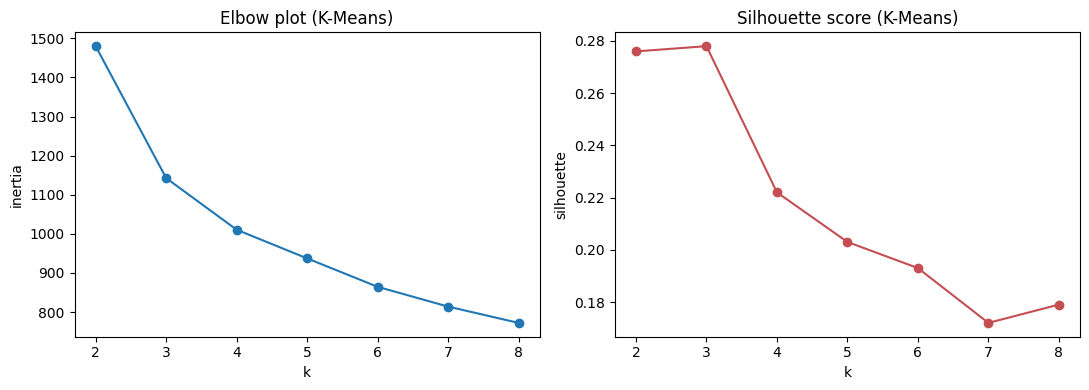

In [65]:
# elbow and silhouette for k = 2 to 8
k_results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=seed)
    lab = km.fit_predict(x)
    k_results.append({
        'k': k,
        'inertia': round(km.inertia_, 1),
        'silhouette': round(silhouette_score(x, lab), 3),
        'smallest_cluster': int(np.bincount(lab).min()),
        'largest_cluster': int(np.bincount(lab).max())
    })
k_results = pd.DataFrame(k_results)
print(k_results.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_results['k'], k_results['inertia'], marker='o')
axes[0].set_title('Elbow plot (K-Means)')
axes[0].set_xlabel('k')
axes[0].set_ylabel('inertia')
axes[1].plot(k_results['k'], k_results['silhouette'], marker='o', color='#C44E52')
axes[1].set_title('Silhouette score (K-Means)')
axes[1].set_xlabel('k')
axes[1].set_ylabel('silhouette')
plt.tight_layout()
plt.savefig('figures/fig_kmeans_elbow_silhouette.png', dpi=150)
plt.show()

In [66]:
# pick k (override with a number if the plots and profiles support a different choice)
chosen_k = None

if chosen_k is None:
    ok = k_results[(k_results['k'].between(3, 6)) & (k_results['smallest_cluster'] >= 0.05 * len(analysis))]
    if len(ok) == 0:
        ok = k_results[k_results['k'].between(3, 6)]
    chosen_k = int(ok.sort_values('silhouette', ascending=False).iloc[0]['k'])
print('chosen k:', chosen_k)

kmeans = KMeans(n_clusters=chosen_k, n_init=50, random_state=seed)
km_labels = kmeans.fit_predict(x)
print('cluster sizes:', np.bincount(km_labels))
print('silhouette:', round(silhouette_score(x, km_labels), 3))

chosen k: 3
cluster sizes: [211 111  67]
silhouette: 0.278


In [67]:
# stability: refit with 10 different seeds and compare to the final labels
aris = []
for s in range(10):
    lab = KMeans(n_clusters=chosen_k, n_init=10, random_state=s).fit_predict(x)
    aris.append(adjusted_rand_score(km_labels, lab))
print('adjusted rand index across seeds: mean', round(np.mean(aris), 3), 'min', round(np.min(aris), 3))

adjusted rand index across seeds: mean 0.973 min 0.863


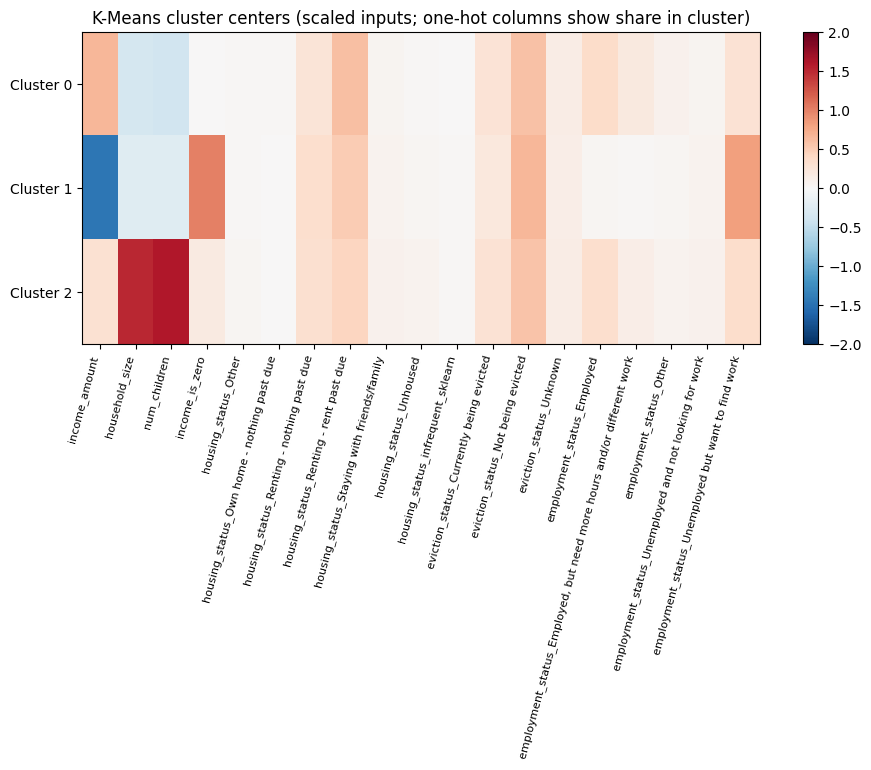

                                                                            Cluster 0  Cluster 1  Cluster 2
money__income_amount                                                             0.66      -1.44       0.30
count__household_size                                                           -0.35      -0.24       1.51
count__num_children                                                             -0.38      -0.25       1.60
flag__income_is_zero                                                             0.00       1.00       0.18
cat__housing_status_Other                                                        0.02       0.03       0.04
cat__housing_status_Own home - nothing past due                                  0.02      -0.00       0.01
cat__housing_status_Renting - nothing past due                                   0.27       0.34       0.31
cat__housing_status_Renting - rent past due                                      0.60       0.50       0.43
cat__housing_status_Staying 

In [68]:
# which inputs drive each cluster: k-means centers on the scaled inputs
centers = pd.DataFrame(kmeans.cluster_centers_, columns=x_names)
centers.index = ['Cluster ' + str(i) for i in range(chosen_k)]

fig, ax = plt.subplots(figsize=(max(8, 0.5 * len(x_names)), 0.6 * chosen_k + 6))
im = ax.imshow(centers.values, aspect='auto', cmap='RdBu_r', vmin=-2, vmax=2)
ax.set_xticks(range(len(x_names)))
ax.set_xticklabels([n.split('__', 1)[-1] for n in x_names], rotation=75, ha='right', fontsize=8)
ax.set_yticks(range(chosen_k))
ax.set_yticklabels(centers.index)
ax.set_title('K-Means cluster centers (scaled inputs; one-hot columns show share in cluster)')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig('figures/fig_kmeans_centers.png', dpi=150)
plt.show()
print(centers.round(2).T.to_string())

We compared k = 2 through 8, and the silhouette scores were 0.276, 0.278, 0.222, 0.203, 0.193, 0.172, and 0.179, so we chose k = 3 because it had the highest score and the score drops after k = 3. The elbow curve also bends around k = 3–4. With k = 3 there are three groups we can describe clearly, and the large-household group only appears at k = 3. When we re-ran K-Means with 10 different seeds, it gave us nearly the same clusters (adjusted Rand index 0.973).

7. Apply hierarchical/agglomerative clustering to the same prepared data. Include a dendrogram for a readable sample or another appropriate visualization. Compare whether the broad patterns are similar to K-Means; explain differences rather than expecting identical labels.

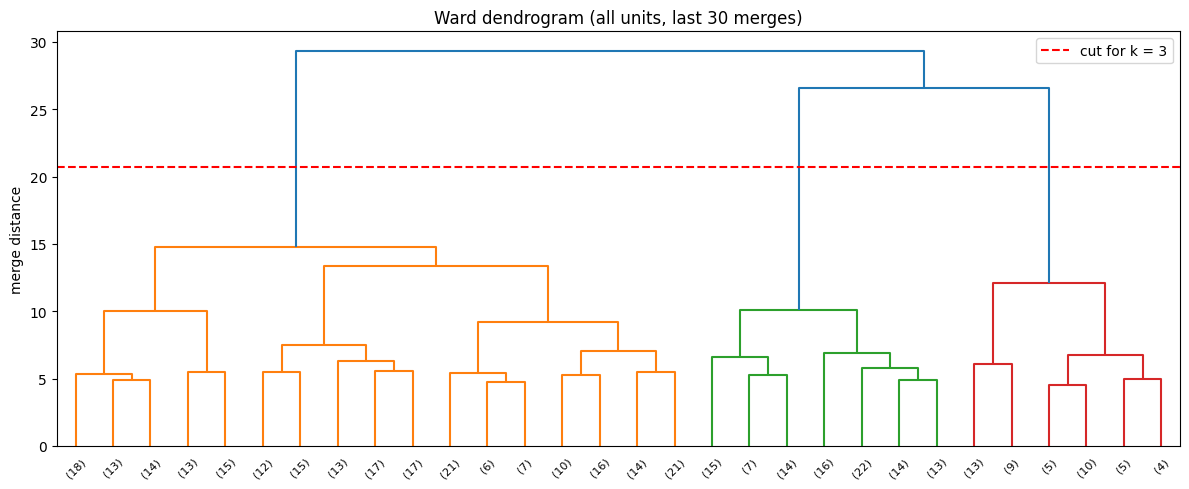

In [69]:
# ward linkage on the same prepared matrix; dendrogram of all units (top merges) with the cut for chosen_k
z = linkage(x, method='ward')
cut = (z[-chosen_k, 2] + z[-chosen_k + 1, 2]) / 2

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(z, truncate_mode='lastp', p=30, ax=ax, no_labels=False, leaf_font_size=8)
ax.axhline(cut, color='red', linestyle='--', label='cut for k = ' + str(chosen_k))
ax.set_title('Ward dendrogram (all units, last 30 merges)')
ax.set_ylabel('merge distance')
ax.legend()
plt.tight_layout()
plt.savefig('figures/fig_dendrogram_full.png', dpi=150)
plt.show()

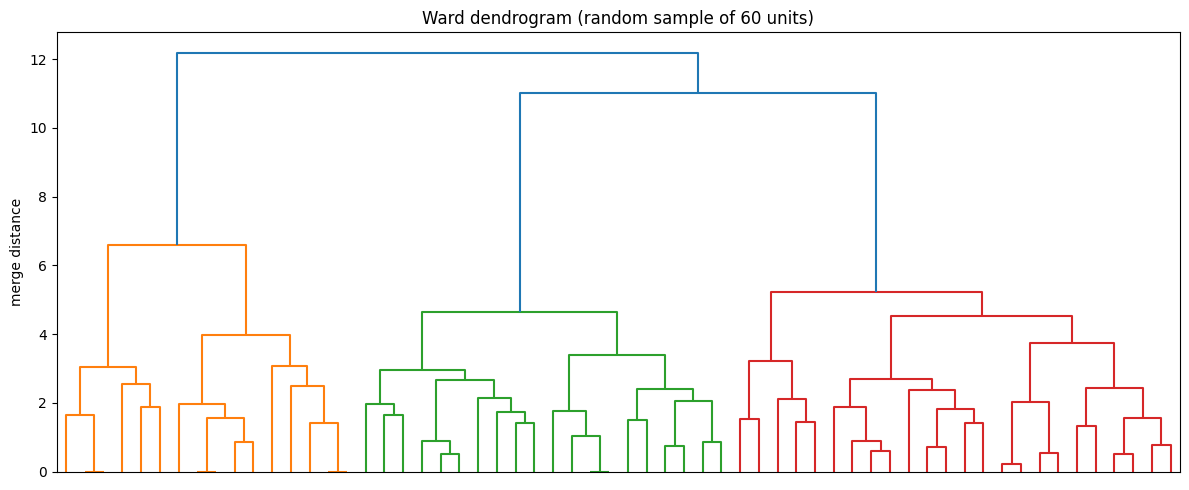

In [70]:
# readable dendrogram on a random sample of 60 units
rng = np.random.default_rng(seed)
sample_idx = rng.choice(len(x), size=min(60, len(x)), replace=False)
z_sample = linkage(x[sample_idx], method='ward')

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(z_sample, ax=ax, no_labels=True)
ax.set_title('Ward dendrogram (random sample of ' + str(len(sample_idx)) + ' units)')
ax.set_ylabel('merge distance')
plt.tight_layout()
plt.savefig('figures/fig_dendrogram_sample.png', dpi=150)
plt.show()

In [71]:
# agglomerative clustering at the same k, relabeled to line up with the k-means clusters
hc_raw = AgglomerativeClustering(n_clusters=chosen_k, linkage='ward').fit_predict(x)

overlap = pd.crosstab(hc_raw, km_labels).reindex(index=range(chosen_k), columns=range(chosen_k), fill_value=0)
row_ind, col_ind = linear_sum_assignment(-overlap.values)
relabel = dict(zip(row_ind, col_ind))
hc_labels = np.array([relabel[v] for v in hc_raw])

print('hierarchical cluster sizes:', np.bincount(hc_labels, minlength=chosen_k))
print('hierarchical silhouette:', round(silhouette_score(x, hc_labels), 3))
print('k-means silhouette:', round(silhouette_score(x, km_labels), 3))
print('adjusted rand index (k-means vs hierarchical):', round(adjusted_rand_score(km_labels, hc_labels), 3))
print('units with the same cluster in both methods:', round((km_labels == hc_labels).mean() * 100, 1), '%')
print()
print(pd.crosstab(pd.Series(km_labels, name='k-means'), pd.Series(hc_labels, name='hierarchical'), margins=True))

hierarchical cluster sizes: [242 101  46]
hierarchical silhouette: 0.276
k-means silhouette: 0.278
adjusted rand index (k-means vs hierarchical): 0.758
units with the same cluster in both methods: 89.5 %

hierarchical    0    1   2  All
k-means                        
0             211    0   0  211
1               0  101  10  111
2              31    0  36   67
All           242  101  46  389


In [72]:
# silhouette of hierarchical clustering across k for comparison with k-means
hc_rows = []
for k in range(2, 9):
    lab = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(x)
    hc_rows.append({'k': k, 'hierarchical_silhouette': round(silhouette_score(x, lab), 3)})
print(k_results[['k', 'silhouette']].merge(pd.DataFrame(hc_rows), on='k').rename(columns={'silhouette': 'kmeans_silhouette'}).to_string(index=False))

 k  kmeans_silhouette  hierarchical_silhouette
 2              0.276                    0.259
 3              0.278                    0.276
 4              0.222                    0.183
 5              0.203                    0.182
 6              0.193                    0.186
 7              0.172                    0.168
 8              0.179                    0.172


variance explained by 2 components: 62.8 %


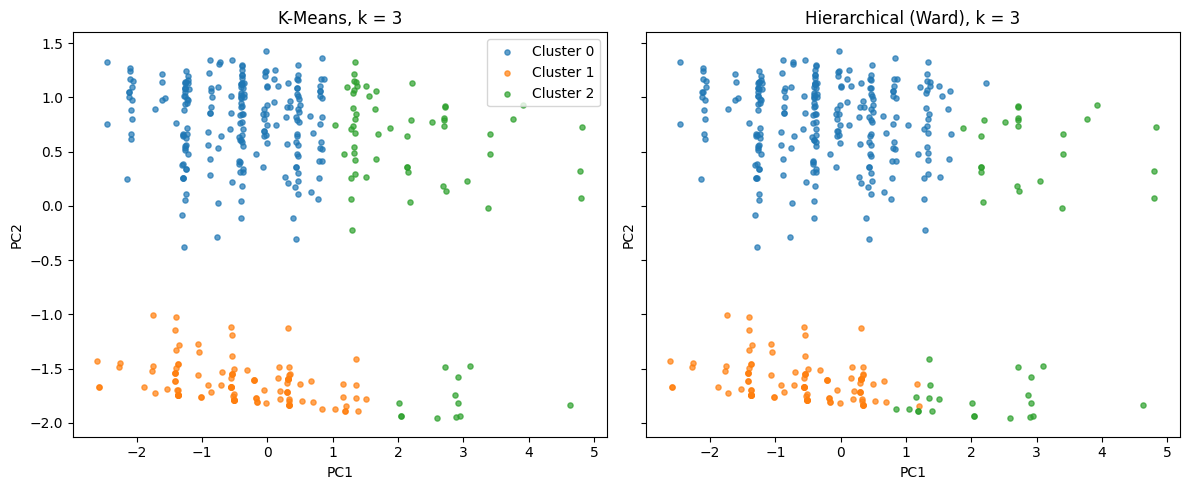

In [73]:
# 2-D PCA view of both clusterings (for visualization only)
pca = PCA(n_components=2, random_state=seed)
pts = pca.fit_transform(x)
print('variance explained by 2 components:', round(pca.explained_variance_ratio_.sum() * 100, 1), '%')

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, lab, title in [(axes[0], km_labels, 'K-Means'), (axes[1], hc_labels, 'Hierarchical (Ward)')]:
    for c in range(chosen_k):
        mask = lab == c
        ax.scatter(pts[mask, 0], pts[mask, 1], s=14, alpha=0.7, label='Cluster ' + str(c))
    ax.set_title(title + ', k = ' + str(chosen_k))
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
axes[0].legend()
plt.tight_layout()
plt.savefig('figures/fig_pca_clusters.png', dpi=150)
plt.show()

Both methods found similar broad patterns: 89.5% of people were placed in the same cluster by both methods, with an adjusted Rand index of 0.758. Their silhouette scores were 0.278 and 0.276, so neither method separated the groups better. The main difference is that hierarchical clustering put fewer people in the large-household group (46 vs. 67) and the \$0-income group (101 vs. 111), and more in the main group (242 vs. 211). In the crosstab and PCA plot, 31 people shifted at the boundary between the main group and the large-household group, and 10 large households with $0 income shifted from the \$0-income group into the large-household group. The dendrogram shows the sample splitting into three main branches, which supports k = 3.

8. Profile each final cluster using understandable tables and plots: cluster size, important numerical summaries, and relevant category proportions. Give clusters neutral descriptive names based only on measured attributes, not stigmatizing labels.

In [74]:
# neutral cluster names based only on measured attributes
cluster_names = {
    0: 'Reported income, mostly employed, smaller households',
    1: '$0 reported income, seeking work',
    2: 'Larger households with more children'
}

analysis['cluster'] = km_labels
analysis['cluster_hc'] = hc_labels
analysis['cluster_name'] = [cluster_names.get(c, 'Cluster ' + str(c)) for c in km_labels]

sizes = analysis['cluster_name'].value_counts().sort_index()
size_table = pd.DataFrame({'n': sizes, 'pct': (sizes / len(analysis) * 100).round(1)})
print(size_table.to_string())

                                                        n   pct
cluster_name                                                   
$0 reported income, seeking work                      111  28.5
Larger households with more children                   67  17.2
Reported income, mostly employed, smaller households  211  54.2


In [75]:
# numeric summaries by cluster
agg = {}
if 'income_amount' in num_features:
    agg['income_median'] = ('income_amount', 'median')
    agg['income_mean'] = ('income_amount', 'mean')
    agg['income_zero_pct'] = ('income_amount', lambda s: round((s == 0).mean() * 100, 1))
    agg['income_missing_pct'] = ('income_amount', lambda s: round(s.isna().mean() * 100, 1))
for f in inputs_count:
    agg[f + '_mean'] = (f, 'mean')
if 'past_due_rent' in num_features:
    agg['past_due_recorded_pct'] = ('past_due_rent', lambda s: round(s.notna().mean() * 100, 1))
    agg['past_due_median_if_recorded'] = ('past_due_rent', 'median')

num_profile = analysis.groupby('cluster_name').agg(**agg).round(1)
num_profile.to_csv('outputs/cluster_numeric_profile.csv')
print(num_profile.T.to_string())

cluster_name                 $0 reported income, seeking work  Larger households with more children  Reported income, mostly employed, smaller households
income_median                                             0.0                                1100.0                                                1500.0
income_mean                                               0.0                                1435.8                                                1708.3
income_zero_pct                                         100.0                                  17.9                                                   0.0
income_missing_pct                                        0.0                                   0.0                                                   0.0
household_size_mean                                       3.3                                   6.9                                                   3.1
num_children_mean                                         2.0               

housing_status (% of cluster)
housing_status                                        Extended-stay hotel / short-term  Other  Own home - mortgage past due  Own home - nothing past due  Renting - nothing past due  Renting - rent past due  Staying with friends/family  Unhoused
cluster_name                                                                                                                                                                                                                                        
$0 reported income, seeking work                                                   1.8    2.7                           0.0                          0.0                        34.2                     50.5                          7.2       3.6
Larger households with more children                                               1.5    4.5                           1.5                          1.5                        31.3                     43.3                          9.0 

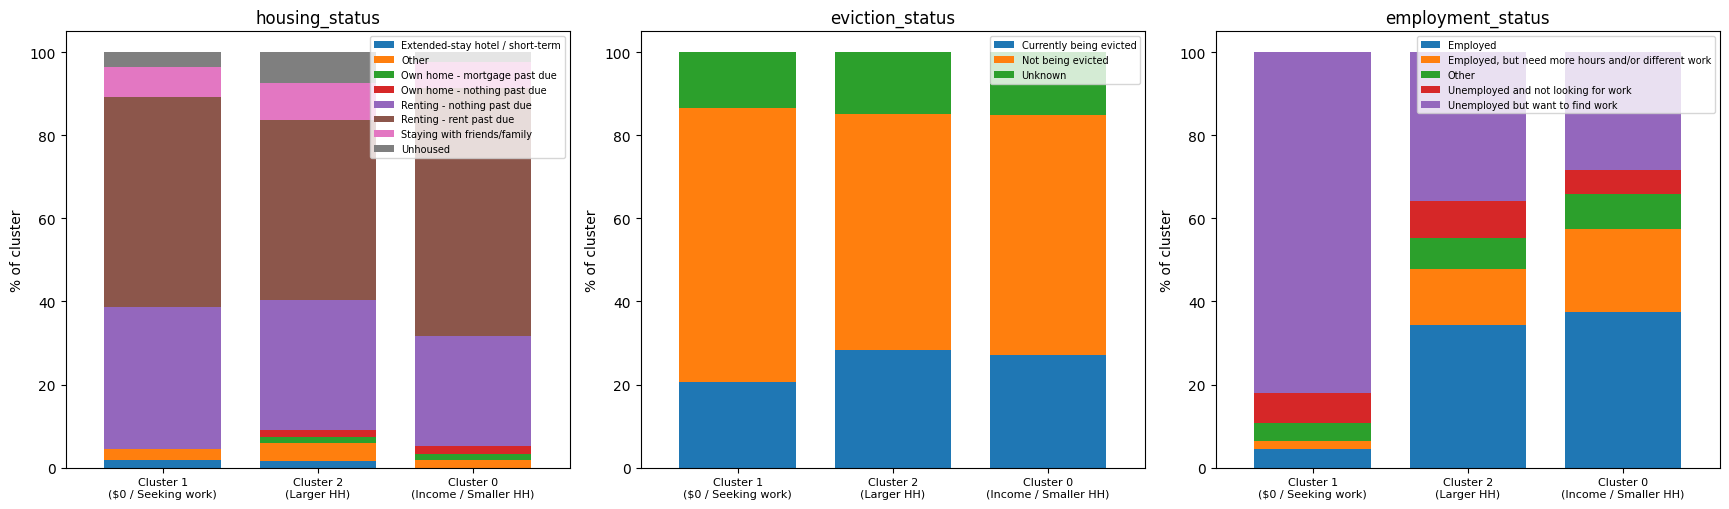

In [76]:
# category proportions (% of each cluster) for every categorical input
for f in cat_features:
    tab = pd.crosstab(analysis['cluster_name'], analysis[f], normalize='index') * 100
    print(f, '(% of cluster)')
    print(tab.round(1).to_string())
    print()

short_labels = {
    'Reported income, mostly employed, smaller households': 'Cluster 0\n(Income / Smaller HH)',
    '$0 reported income, seeking work': 'Cluster 1\n($0 / Seeking work)',
    'Larger households with more children': 'Cluster 2\n(Larger HH)'
}

if len(cat_features) > 0:
    fig, axes = plt.subplots(1, len(cat_features), figsize=(5.8 * len(cat_features), 5.2), squeeze=False)
    for i, f in enumerate(cat_features):
        tab = pd.crosstab(analysis['cluster_name'], analysis[f], normalize='index') * 100
        tab.index = [short_labels.get(idx, idx) for idx in tab.index]
        tab.plot(kind='bar', stacked=True, ax=axes[0][i], width=0.75)
        axes[0][i].set_title(f)
        axes[0][i].set_ylabel('% of cluster')
        axes[0][i].set_xlabel('')
        axes[0][i].tick_params(axis='x', rotation=0, labelsize=8)
        axes[0][i].legend(fontsize=7, loc='upper right')
    plt.tight_layout()
    plt.savefig('figures/fig_cluster_categories.png', dpi=150)
    plt.show()

In [77]:
# describe-only fields: urgency proxy and sensitive fields (never used to form clusters)
print('urgent_housing_proxy by cluster (counts):')
print(pd.crosstab(analysis['cluster_name'], analysis['urgent_housing_proxy'].fillna('Unknown'), margins=True))
print()
print('urgent_housing_proxy by cluster (% of cluster):')
print((pd.crosstab(analysis['cluster_name'], analysis['urgent_housing_proxy'].fillna('Unknown'), normalize='index') * 100).round(1))
print()

sensitive_cols = [c for c, r in roles.items() if 'sensitive' in r and c in analysis.columns]
if len(sensitive_cols) == 0:
    keys = ['age', 'gender', 'race', 'ethnic', 'language', 'health']
    sensitive_cols = [c for c in analysis.columns if any(k in c.lower() for k in keys) and c not in num_features + cat_features]
print('sensitive fields (describe only):', sensitive_cols)
print()

for c in sensitive_cols:
    vals = pd.to_numeric(analysis[c], errors='coerce')
    unique_vals = set(vals.dropna().unique())
    if len(unique_vals) > 0 and unique_vals.issubset({0, 1}):
        print(c, '(% Yes by cluster):')
        print((vals.groupby(analysis['cluster_name']).mean() * 100).round(1).to_string())
    elif mostly_numeric(c):
        print(c, 'median by cluster:')
        print(vals.groupby(analysis['cluster_name']).median().round(1).to_string())
    elif analysis[c].nunique() <= 12:
        print(c, '(% of cluster)')
        print((pd.crosstab(analysis['cluster_name'], analysis[c].fillna('Unknown'), normalize='index') * 100).round(1).to_string())
    print()

urgent_housing_proxy by cluster (counts):
urgent_housing_proxy                                   No  Unknown  Yes  All
cluster_name                                                                
$0 reported income, seeking work                       69       15   27  111
Larger households with more children                   35        9   23   67
Reported income, mostly employed, smaller households  117       32   62  211
All                                                   221       56  112  389

urgent_housing_proxy by cluster (% of cluster):
urgent_housing_proxy                                    No  Unknown   Yes
cluster_name                                                             
$0 reported income, seeking work                      62.2     13.5  24.3
Larger households with more children                  52.2     13.4  34.3
Reported income, mostly employed, smaller households  55.5     15.2  29.4

sensitive fields (describe only): ['hh_pregnant_postpartum', 'hh_disability'

In [78]:
# snap/tanf share by cluster, overall and among employed people (describe only)
snap = pd.to_numeric(analysis['inc_src_snap_tanf'], errors='coerce')
employed = analysis['employment_status'].str.startswith('Employed')

snap_table = pd.DataFrame({
    'n': analysis.groupby('cluster_name').size(),
    'snap_count': snap.groupby(analysis['cluster_name']).sum(),
    'snap_pct': (snap.groupby(analysis['cluster_name']).mean() * 100).round(1),
    'employed_n': employed.groupby(analysis['cluster_name']).sum(),
    'employed_snap_count': snap[employed].groupby(analysis.loc[employed, 'cluster_name']).sum()
})
snap_table['employed_snap_pct'] = (snap_table['employed_snap_count'] / snap_table['employed_n'] * 100).round(1)
snap_table.to_csv('outputs/snap_by_cluster.csv')
print(snap_table.to_string())

                                                        n  snap_count  snap_pct  employed_n  employed_snap_count  employed_snap_pct
cluster_name                                                                                                                       
$0 reported income, seeking work                      111        50.0      45.0           7                  2.0               28.6
Larger households with more children                   67        27.0      40.3          32                 10.0               31.2
Reported income, mostly employed, smaller households  211        78.0      37.7         121                 34.0               28.1


**Reported income, mostly employed, smaller households** (211 people, 54%): This group has a median monthly income of 1,500, the highest of the three clusters. Most are working (37% employed and 20% employed but needing more hours), and their households average 3.1 people with 1.8 children. Among those with past-due rent recorded, 31% (27 of 88) have high arrears of \$3,000 or more.

**\$0 reported income, seeking work** (111 people, 29%): This group has a median income of 0, since everyone in it reported no income. 82% are unemployed but want to work. The average household size is 3.3, with an average of 2 children. Among those with past-due rent recorded, 19% (7 of 36) have high arrears of $3,000 or more.

**Larger households with more children** (67 people, 17%): This group has an average household size of 6.9 and an average of 4.5 children, about double the other two clusters. Their median income is $1,100. 34% are employed and 36% are unemployed but want work. Among those with past-due rent recorded, 38% (10 of 26) have high arrears of $3,000 or more, the highest of the three clusters.

Housing and eviction status were similar across all three clusters, so housing pressure shows up in every group rather than in just one, and what separates the clusters is income, employment and household size.

## Question 1

Different patterns of need: Do the intake records reveal distinct groups based on housing instability, income/employment circumstances, and household composition? What are the defining characteristics of each group, and how stable are they across the two clustering methods?

Yes, the records show three distinct groups, but these groups overlap. Because the silhouette score is 0.28, they are not sharply separated. The groups are defined by income/employment and household composition, not housing. Income and employment separate the \$0-income, seeking-work group from the others, and household composition separates the larger-households group. Housing does not separate them, because housing and eviction status are similar in all three. The groups are fairly stable across the two methods, with 89.5% agreement and an adjusted Rand index of 0.758. K-Means also gave nearly the same clusters across 10 random seeds (0.973), which is close to perfect. The 10.5% of people (41 total) who switch between methods are at two boundaries: 31 between the main group and the large-household group, and 10 large households with $0 income between the $0-income group and the large-household group, so the core of each group is stable while those edges are less certain.

## Question 2

Overlapping pressures: Which challenges tend to appear together? Show the relevant within-cluster comparisons; high_arrears_3000 can be one of them. Do not infer cause and effect.

In [79]:
# high arrears ($3,000+) by cluster, only among units with past-due rent recorded
arrears = analysis['high_arrears_3000']
recorded = arrears.notna() & (arrears.astype(str).str.strip() != '')
arrears_flag = to_bool(arrears)

q10 = pd.DataFrame({
    'units': analysis.groupby('cluster_name').size(),
    'arrears_recorded': recorded.groupby(analysis['cluster_name']).sum(),
    'high_arrears_3000': (arrears_flag & recorded).groupby(analysis['cluster_name']).sum()
})
q10['high_arrears_pct_of_recorded'] = (q10['high_arrears_3000'] / q10['arrears_recorded'] * 100).round(1)
q10.to_csv('outputs/q10_arrears_by_cluster.csv')
print(q10.to_string())

                                                      units  arrears_recorded  high_arrears_3000  high_arrears_pct_of_recorded
cluster_name                                                                                                                  
$0 reported income, seeking work                        111                36                  7                          19.4
Larger households with more children                     67                26                 10                          38.5
Reported income, mostly employed, smaller households    211                88                 27                          30.7


In [80]:
# employment by housing inside each cluster (counts)
if 'employment_status' in cat_features and 'housing_status' in cat_features:
    for name, group in analysis.groupby('cluster_name'):
        print(name, '(n = ' + str(len(group)) + ')')
        print(pd.crosstab(group['employment_status'], group['housing_status'], margins=True))
        print()

$0 reported income, seeking work (n = 111)
housing_status                                       Extended-stay hotel / short-term  Other  Renting - nothing past due  Renting - rent past due  Staying with friends/family  Unhoused  All
employment_status                                                                                                                                                                            
Employed                                                                            0      0                           0                        5                            0         0    5
Employed, but need more hours and/or different work                                 0      0                           1                        1                            0         0    2
Other                                                                               0      0                           2                        3                            0         0    5
Unemplo

In [81]:
# employment by $0 income inside each cluster (counts)
if 'employment_status' in cat_features and 'income_amount' in num_features:
    income_group = np.where(analysis['income_amount'].isna(), 'income missing',
                            np.where(analysis['income_amount'] == 0, '$0 income', 'income > $0'))
    print(pd.crosstab([analysis['cluster_name'], analysis['employment_status']], income_group))

col_0                                                                                                     $0 income  income > $0
cluster_name                                         employment_status                                                          
$0 reported income, seeking work                     Employed                                                     5            0
                                                     Employed, but need more hours and/or different work          2            0
                                                     Other                                                        5            0
                                                     Unemployed and not looking for work                          8            0
                                                     Unemployed but want to find work                            91            0
Larger households with more children                 Employed                                    

Different challenges appear together in each cluster. The arrears-by-cluster table and the employment-by-housing tables for each cluster (above) show these comparisons. In the larger-households cluster, the highest high-arrears rate (38%, 10 of 26 with past-due rent recorded) appears alongside a lower median income of \$1,100. In the $0-income cluster, having no income and being unemployed appear together, but this group had the lowest high-arrears rate at 19% (7 of 36). In the reported-income cluster, most people are employed, but 31% (27 of 88) still have high arrears. These counts are small because past-due rent is only recorded for about 38% of people, so the arrears rates are uncertain. These patterns show which challenges appear together, not that one causes another.

## Question 3

Repeat needs and missing information: Does the distribution of repeat PID contacts (and of linked care-path sub-tickets) differ across the identified patterns? Report counts alongside percentages. PID is name-matched: some sub-tickets carry a different PID from their parent profile. What would you still need to know to distinguish immediate crisis from recurring instability or to evaluate whether assistance improved outcomes?

In [82]:
# repeat contacts by cluster (counts and %)
q11 = pd.DataFrame({
    'units': analysis.groupby('cluster_name').size(),
    'repeat_units': (analysis['n_profiles'] > 1).groupby(analysis['cluster_name']).sum()
})
q11['repeat_pct'] = (q11['repeat_units'] / q11['units'] * 100).round(1)
print(q11.to_string())

                                                      units  repeat_units  repeat_pct
cluster_name                                                                         
$0 reported income, seeking work                        111             6         5.4
Larger households with more children                     67             4         6.0
Reported income, mostly employed, smaller households    211            11         5.2


In [83]:
# link care-path sub-tickets to units through their parent profile's issue key
parent_cols = [c for c in subs.columns if 'parent' in c.lower()]
print('sub-ticket parent column:', parent_cols)

if len(parent_cols) > 0:
    parent_col = parent_cols[0]
    key_to_unit = profiles[['issue_key', 'pid']].copy()
    key_to_unit['unit_id'] = key_to_unit['pid'].astype(str)
    missing = key_to_unit['pid'].isna()
    key_to_unit.loc[missing, 'unit_id'] = 'ticket_' + key_to_unit.loc[missing, 'issue_key'].astype(str)
    key_to_unit = dict(zip(key_to_unit['issue_key'], key_to_unit['unit_id']))

    subs = subs.copy()
    subs['unit_id'] = subs[parent_col].map(key_to_unit)
    print('sub-tickets:', len(subs))
    print('linked to a profile:', subs['unit_id'].notna().sum())
    print('linked to a unit in the analysis table:', subs['unit_id'].isin(analysis['unit_id']).sum())

    # name-matched pid on the sub-ticket vs its parent's pid
    if 'pid' in subs.columns:
        parent_pid = subs[parent_col].map(dict(zip(profiles['issue_key'], profiles['pid'])))
        both = subs['pid'].notna() & parent_pid.notna()
        print('sub-tickets whose pid differs from parent profile pid:', (subs.loc[both, 'pid'].astype(str) != parent_pid[both].astype(str)).sum())

    sub_counts = subs.groupby('unit_id').size().rename('n_subtickets')
    analysis['n_subtickets'] = analysis['unit_id'].map(sub_counts).fillna(0).astype(int)

    q11['units_with_subticket'] = (analysis['n_subtickets'] > 0).groupby(analysis['cluster_name']).sum()
    q11['subticket_pct'] = (q11['units_with_subticket'] / q11['units'] * 100).round(1)
    q11['total_subtickets'] = analysis.groupby('cluster_name')['n_subtickets'].sum()
    q11.to_csv('outputs/q11_repeat_and_subtickets_by_cluster.csv')
    print()
    print(q11.to_string())

    type_cols = [c for c in subs.columns if c == 'issue_type'] + [c for c in subs.columns if ('type' in c.lower() or 'path' in c.lower()) and c != 'issue_type' and 'parent' not in c.lower()]
    if len(type_cols) > 0:
        type_col = type_cols[0]
        linked = subs[subs['unit_id'].isin(analysis['unit_id'])].copy()
        linked['cluster_name'] = linked['unit_id'].map(dict(zip(analysis['unit_id'], analysis['cluster_name'])))
        print()
        print('sub-ticket type (' + type_col + ') by cluster, counts:')
        print(pd.crosstab(linked['cluster_name'], linked[type_col].fillna('Unknown'), margins=True))

sub-ticket parent column: ['parent_issue_key', 'parent_in_file', 'pid_matches_parent']
sub-tickets: 213
linked to a profile: 200
linked to a unit in the analysis table: 200
sub-tickets whose pid differs from parent profile pid: 31

                                                      units  repeat_units  repeat_pct  units_with_subticket  subticket_pct  total_subtickets
cluster_name                                                                                                                                
$0 reported income, seeking work                        111             6         5.4                    49           44.1                64
Larger households with more children                     67             4         6.0                    28           41.8                33
Reported income, mostly employed, smaller households    211            11         5.2                    85           40.3               103

sub-ticket type (care_path_type) by cluster, counts:
care_path

Repeat contacts do not really differ across the clusters. About 5% to 6% of each cluster has more than one profile (11 of 211, 6 of 111, and 4 of 67), which is too few to show a real difference. Sub-tickets are also spread evenly, with about 40–44% of each cluster having at least one (85 of 211, 49 of 111, and 28 of 67). Rent Assistance Care Path is the most common care path in every cluster, with 111 of the 200 linked sub-tickets (followed by House Navigation with 22). There is also a PID problem: out of 213 sub-tickets, 200 link to a profile, and 31 of those have a different PID from their parent. This means repeat counts may not be fully accurate.

Some data that would be needed is dates and status of each visit, housing status recorded every time, what assistance was given and the outcome, and a more reliable person ID than name matching. Dates and status of each visit would tell the difference between a one-time crisis and someone who repeatedly comes back. Recording housing status every time would show how a family’s housing changes over time, which ties back to Part 1, where only 27 of the 150 repeat people had it recorded more than once. The type of assistance given and the outcome afterward would show what help is working and make it easier to measure SLCM’s Reconnect/Rethink/Rebuild stages. A more reliable person ID would fix the name-matching problem, where 31 sub-tickets ended up with a different PID from their parent profile.

## Question 4

SLCM program and policy implications: Propose TWO realistic ways SLCM could investigate or tailor its services. For each, link the recommendation to a plot or statistic and state a limitation. Explain why your clusters should not be used by themselves to determine who receives assistance.

In [84]:
# one-screen recap of the key numbers
print('unit:', unit)
print('rows: start', flow[0][1], '-> final', len(analysis))
print('clustering inputs:', inputs_money + inputs_count + inputs_flag + inputs_cat)
print('chosen k:', chosen_k)
print('k-means silhouette:', round(silhouette_score(x, km_labels), 3))
print('hierarchical silhouette:', round(silhouette_score(x, hc_labels), 3))
print('agreement (adjusted rand index):', round(adjusted_rand_score(km_labels, hc_labels), 3))
print()
print(size_table.to_string())
print()
print('figures saved in figures/, summary tables saved in outputs/ (no case-level records)')

unit: person
rows: start 426 -> final 389
clustering inputs: ['income_amount', 'household_size', 'num_children', 'income_is_zero', 'housing_status', 'eviction_status', 'employment_status']
chosen k: 3
k-means silhouette: 0.278
hierarchical silhouette: 0.276
agreement (adjusted rand index): 0.758

                                                        n   pct
cluster_name                                                   
$0 reported income, seeking work                      111  28.5
Larger households with more children                   67  17.2
Reported income, mostly employed, smaller households  211  54.2

figures saved in figures/, summary tables saved in outputs/ (no case-level records)


Two ways SLCM could investigate or tailor its services are by offering rent assistance and housing support screening to every group and by collecting past-due rent and housing status for everyone at every visit. Offering rent assistance and housing support screening to every group would help because housing and eviction status are similar in all three clusters, as shown in the cluster category chart (fig_cluster_categories.png). Rent Assistance is also already the most common care path, with 111 of 200 linked sub-tickets (and House Navigation is second with 22). A limitation is that housing status is only recorded once per person, so a person’s housing could change and we wouldn’t know. Collecting past-due rent and housing status at every visit would improve how SLCM investigates needs, because past-due rent is missing for 61.4% of people. The main limitation is that it would add work for staff at intake.

Clusters should not decide who gets help because real need is decided case by case, and the clusters are built from incomplete intake answers. A family in any cluster should be reviewed by a worker, because anyone could be facing eviction: 21% to 28% are currently being evicted in every cluster. The clusters are also made from many unknowns and missing past-due rent, which could easily place a family in the wrong group, so they might not get the help they need or might be treated as lower need than they are.

## What Did You Learn?

The biggest discovery we ran into is that housing doesn’t separate the groups the way we thought. We expected housing to be a main difference, but it is almost the same in every cluster. What really separates families is income, employment, and household size.

Something unexpected is that the $0-income group had the lowest high-arrears rate at 19%, compared to 31% in the reported-income, mostly employed group. This suggests that having a job does not mean fewer arrears, although the 19% is based on only 7 of 36 people, so it is uncertain. This matches what we found in Part 1, where many employed families still relied on SNAP/TANF.

The data cannot answer whether SLCM’s help actually worked or why these patterns happen. There is no outcome data, so we cannot measure SLCM’s effectiveness, and the data does not show cause and effect.

One suggestion for SLCM’s future data collection is to record housing status and past-due rent at every visit, so they can see how a family’s situation changes. There should also be a recorded check-up at about 3, 6, and 12 months after intake, which lines up with SLCM’s Reconnect/Rethink/Rebuild stages.